In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import json

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetV2B1
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam 
from tensorflow.keras.losses import CategoricalCrossentropy
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [3]:
train_dir = "dataset/train"
test_dir = "dataset/test"

IMG_SIZE = (192, 192)
BATCH_SIZE = 32
SEED = 42

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 12271 files belonging to 7 classes.
Found 3068 files belonging to 7 classes.
Classes: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
Number of classes: 7


In [5]:
class_indices = {name: i for i, name in enumerate(class_names)}

with open("labels.json", "w") as f:
    json.dump(class_indices, f)

print("labels.json saved")

labels.json saved


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [7]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.12),
    layers.RandomContrast(0.12),
    layers.RandomTranslation(0.08, 0.08)
], name="augmentation")

In [8]:
base_model = EfficientNetV2B1(
    include_top=False,
    weights="imagenet",
    input_shape=(192, 192, 3)
)

for layer in base_model.layers[:180]:
    layer.trainable = False

for layer in base_model.layers[180:]:
    layer.trainable = True

In [9]:
inputs = tf.keras.Input(shape=(192, 192, 3))

x = data_augmentation(inputs)

# preprocessing is built into EfficientNetV2
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

model = Model(inputs, outputs)

In [10]:
model.compile(
    optimizer=Adam(learning_rate=2e-5),
    loss=CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b1 (Functional)  │ (None, 6, 6, 1280)     │     6,931,124 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,297,979 (27.84 MB)

 Trainable params: 5,618,559 (21.43 MB)

 Non-trainable params: 1,679,420 (6.41 MB)

In [11]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        "best_model_B.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

In [12]:
history = model.fit(
    train_ds,
    epochs=35,
    validation_data=test_ds,
    callbacks=callbacks
)

Epoch 1/35
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.1656 - loss: 2.5635
Epoch 1: val_accuracy improved from None to 0.43253, saving model to best_model_B.keras
384/384 ━━━━━━━━━━━━━━━━━━━━ 188s 436ms/step - accuracy: 0.2188 - loss: 2.3037 - val_accuracy: 0.4325 - val_loss: 1.6164 - learning_rate: 2.0000e-05
Epoch 2/35
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - accuracy: 0.3449 - loss: 1.9425
Epoch 2: val_accuracy improved from 0.43253 to 0.50391, saving model to best_model_B.keras
384/384 ━━━━━━━━━━━━━━━━━━━━ 165s 429ms/step - accuracy: 0.3651 - loss: 1.8977 - val_accuracy: 0.5039 - val_loss: 1.4875 - learning_rate: 2.0000e-05
Epoch 3/35
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.4117 - loss: 1.7682
Epoch 3: val_accuracy improved from 0.50391 to 0.55378, saving model to best_model_B.keras
384/384 ━━━━━━━━━━━━━━━━━━━━ 166s 433ms/step - accuracy: 0.4233 - loss: 1.7371 - val_accuracy: 0.5538 - val_loss: 1.3977 - learning_rate: 2.0000e-05
Epoch 4/35
384/384 

In [13]:
model = tf.keras.models.load_model("best_model_B.keras")
print("Best Model B loaded")

Best Model B loaded


In [14]:
loss, accuracy = model.evaluate(test_ds)
print(f"Model B Accuracy: {accuracy*100:.2f}%")
print(f"Model B Loss: {loss:.4f}")

96/96 ━━━━━━━━━━━━━━━━━━━━ 23s 199ms/step - accuracy: 0.7914 - loss: 0.9219
Model B Accuracy: 79.14%
Model B Loss: 0.9219


In [15]:
model.save("model_B.keras")
print("Model B saved successfully")

Model B saved successfully


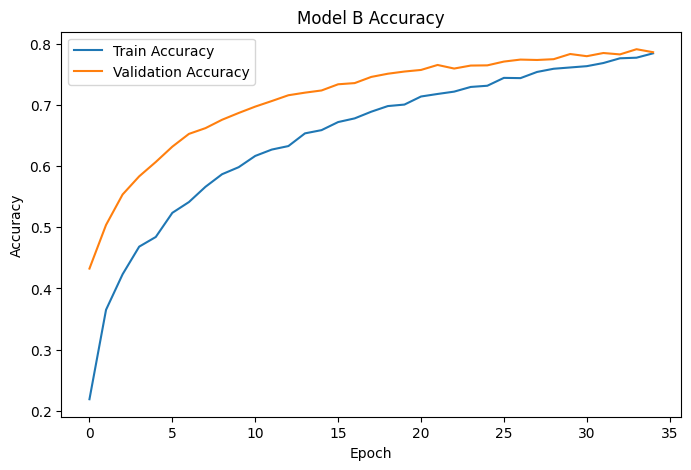

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model B Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

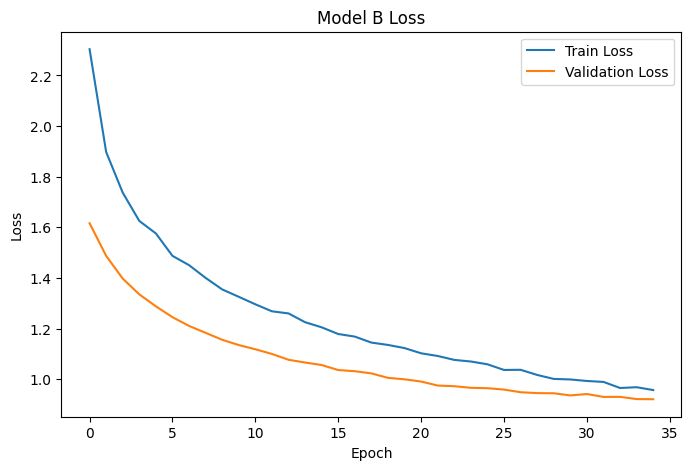

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model B Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

96/96 ━━━━━━━━━━━━━━━━━━━━ 23s 217ms/step


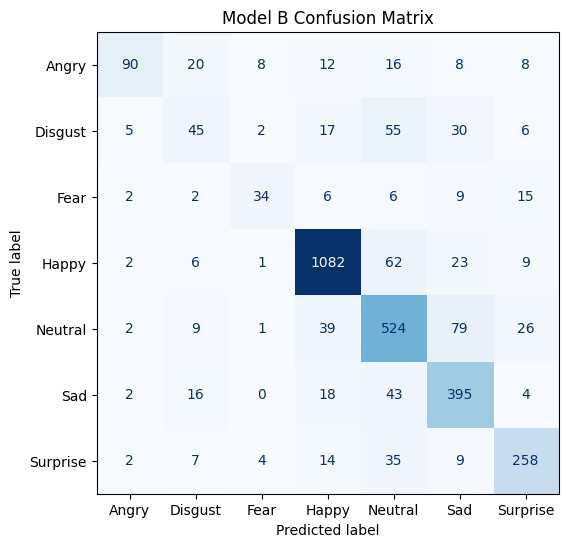

In [18]:
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true_classes = np.argmax(y_true, axis=1)

y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_true_classes, y_pred_classes)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Model B Confusion Matrix")
plt.show()

In [19]:
print(classification_report(
    y_true_classes,
    y_pred_classes,
    target_names=class_names
))

              precision    recall  f1-score   support

       Angry       0.86      0.56      0.67       162
     Disgust       0.43      0.28      0.34       160
        Fear       0.68      0.46      0.55        74
       Happy       0.91      0.91      0.91      1185
     Neutral       0.71      0.77      0.74       680
         Sad       0.71      0.83      0.77       478
    Surprise       0.79      0.78      0.79       329

    accuracy                           0.79      3068
   macro avg       0.73      0.66      0.68      3068
weighted avg       0.79      0.79      0.79      3068

